In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


In [2]:
df_B = pd.read_csv('mercedes_cars.csv')
df_a=df_B.copy()

In [3]:
df_B.head(10)

,model,year,price_eur,mileage_km,fuel_type,transmission,engine_size_l,horsepower,previous_owners
0,S-Class,2024.0,98853.0,19381.0,Petrol,Automatic,3.0,356.0,1.0
1,CLA,2021.0,30306.0,48532.0,Diesel,Automatic,1.9,226.0,1.0
2,GLC,2021.0,34221.0,60837.0,Petrol,Automatic,2.1,223.0,1.0
3,C-Class,2013.0,7160.0,168143.0,Diesel,Manual,2.1,166.0,3.0
4,A-Class,2012.0,5383.0,122613.0,Petrol,Automatic,1.7,166.0,3.0
5,S-Class,2015.0,29339.0,60030.0,Petrol,Automatic,2.9,330.0,1.0
6,C-Class,2020.0,22106.0,58412.0,Hybrid,Automatic,1.9,199.0,1.0
7,C-Class,2020.0,21023.0,52357.0,Diesel,Automatic,2.0,191.0,1.0
8,A-Class,2016.0,9850.0,142032.0,Diesel,Manual,1.5,173.0,2.0
9,C-Class,2017.0,12519.0,116892.0,Diesel,Automatic,1.9,198.0,2.0


In [4]:
df_B.duplicated().sum()

np.int64(20)

In [5]:
df_a.drop_duplicates(inplace=True)

In [6]:
df_a.info()

<class 'pandas.DataFrame'>
Index: 4980 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   model            4980 non-null   str    
 1   year             4931 non-null   float64
 2   price_eur        4831 non-null   float64
 3   mileage_km       4781 non-null   float64
 4   fuel_type        4881 non-null   str    
 5   transmission     4881 non-null   str    
 6   engine_size_l    4534 non-null   float64
 7   horsepower       4831 non-null   float64
 8   previous_owners  4831 non-null   float64
dtypes: float64(6), str(3)
memory usage: 389.1 KB


In [7]:
df_a.isnull().sum()

model                0
year                49
price_eur          149
mileage_km         199
fuel_type           99
transmission        99
engine_size_l      446
horsepower         149
previous_owners    149
dtype: int64

In [8]:
df_a.describe()

,year,price_eur,mileage_km,engine_size_l,horsepower,previous_owners
count,4931.000000,4831.000000,4781.000000,4534.000000,4831.000000,4831.000000
mean,2018.815453,28293.616436,83844.416858,2.103485,243.694059,1.912233
std,3.911186,20683.909324,70208.635935,0.612720,84.295190,1.039667
min,2010.000000,733.000000,300.000000,1.400000,112.000000,1.000000
25%,2016.000000,13770.000000,32618.000000,1.700000,178.000000,1.000000
50%,2020.000000,23811.000000,66884.000000,2.000000,225.000000,2.000000
75%,2022.000000,36893.000000,117837.000000,2.100000,274.000000,2.000000
max,2024.000000,334357.000000,750000.000000,6.000000,780.000000,10.000000


In [9]:
for col in df_a.select_dtypes(include=["float64"]).columns:
    df_a[col] = df_a[col].fillna(df_a[col].median())

In [10]:
df_a.isnull().sum()

model               0
year                0
price_eur           0
mileage_km          0
fuel_type          99
transmission       99
engine_size_l       0
horsepower          0
previous_owners     0
dtype: int64

In [11]:
for col in ['transmission','fuel_type']:
    df_a[col] = df_a[col].fillna(df_a[col].mode()[0])
    

In [12]:
num_cols = ['price_eur', 'mileage_km', 'engine_size_l', 'horsepower', 'previous_owners']

for col in num_cols:
    Q1 = df_a[col].quantile(0.25)
    Q3 = df_a[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_a[col] = df_a[col].clip(lower=lower_bound, upper=upper_bound)
    outliers = df_a[(df_a[col] < lower_bound) | (df_a[col] > upper_bound)]


In [13]:
outliers

,model,year,price_eur,mileage_km,fuel_type,transmission,engine_size_l,horsepower,previous_owners


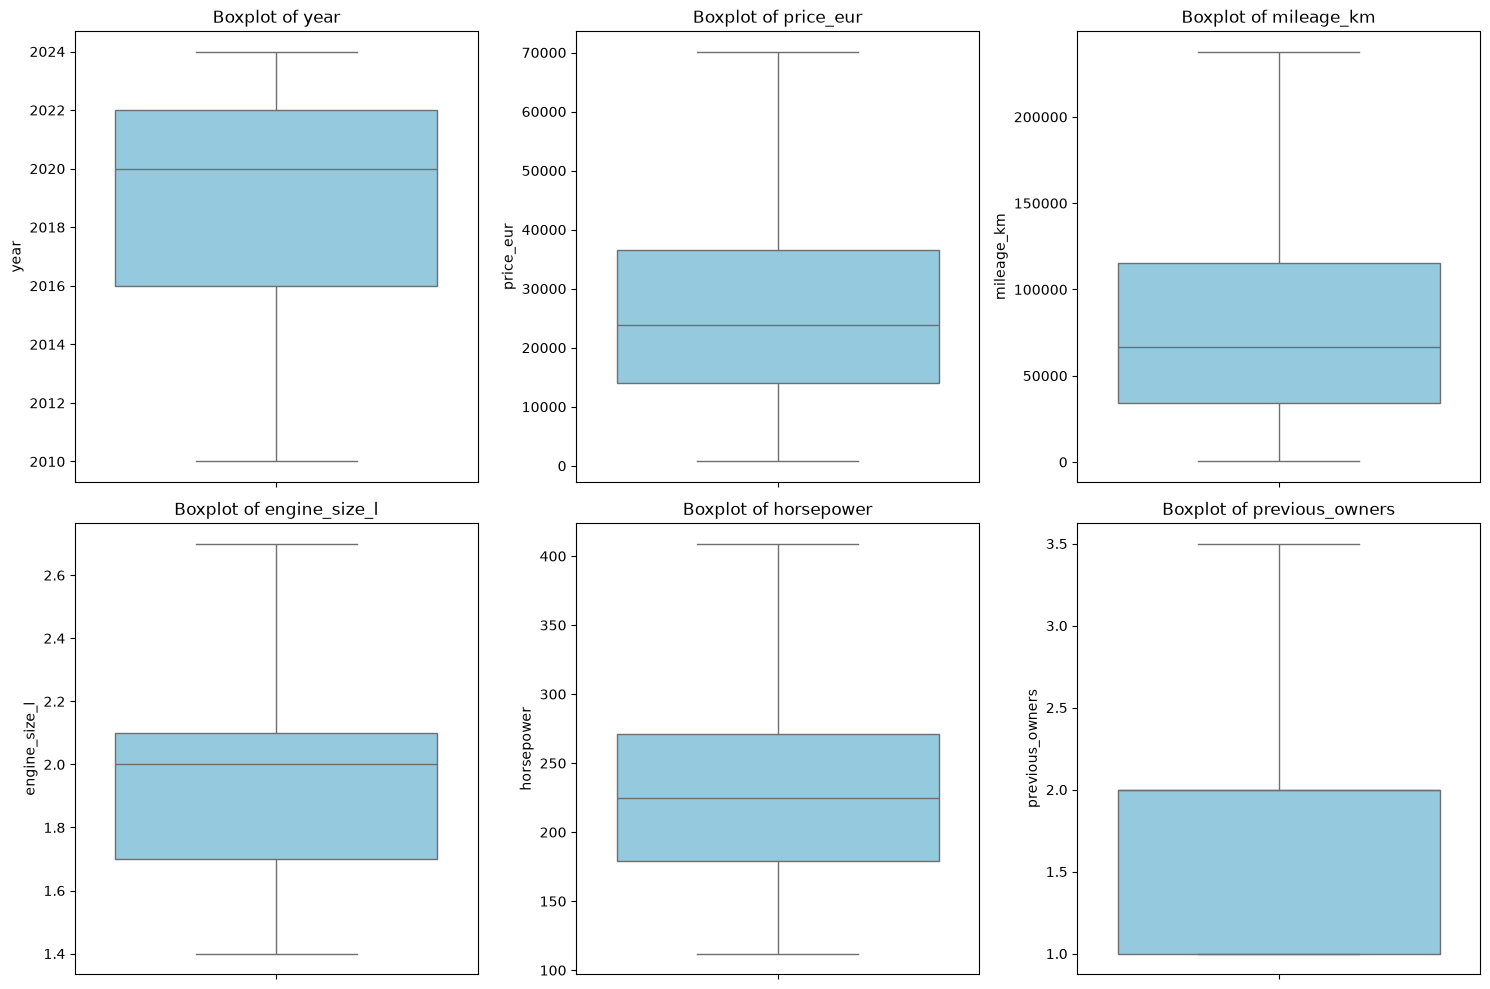

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df_a.select_dtypes(include=['float64', 'int64']).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_a[col], color='skyblue')
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [15]:
df_B.rename(columns={
    'fuel_type': 'fuelType',
    'mileage_km': 'mileage'
}, inplace=True)

In [16]:
df_a.info()

<class 'pandas.DataFrame'>
Index: 4980 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   model            4980 non-null   str    
 1   year             4980 non-null   float64
 2   price_eur        4980 non-null   float64
 3   mileage_km       4980 non-null   float64
 4   fuel_type        4980 non-null   str    
 5   transmission     4980 non-null   str    
 6   engine_size_l    4980 non-null   float64
 7   horsepower       4980 non-null   float64
 8   previous_owners  4980 non-null   float64
dtypes: float64(6), str(3)
memory usage: 389.1 KB


In [17]:
df_a.describe()

,year,price_eur,mileage_km,engine_size_l,horsepower,previous_owners
count,4980.000000,4980.000000,4980.000000,4980.000000,4980.000000,4980.000000
mean,2018.827108,27206.336697,81112.122615,2.005944,240.507430,1.850803
std,3.893649,16895.880161,58993.971469,0.350303,75.202386,0.823698
min,2010.000000,733.000000,300.000000,1.400000,112.000000,1.000000
25%,2016.000000,14017.250000,33970.000000,1.700000,179.000000,1.000000
50%,2020.000000,23811.000000,66884.000000,2.000000,225.000000,2.000000
75%,2022.000000,36477.250000,115534.250000,2.100000,271.000000,2.000000
max,2024.000000,70167.250000,237880.625000,2.700000,409.000000,3.500000


In [18]:
df_a['price_eur'].nunique()

4407

In [19]:
len(df_a['price_eur'].unique())

4407

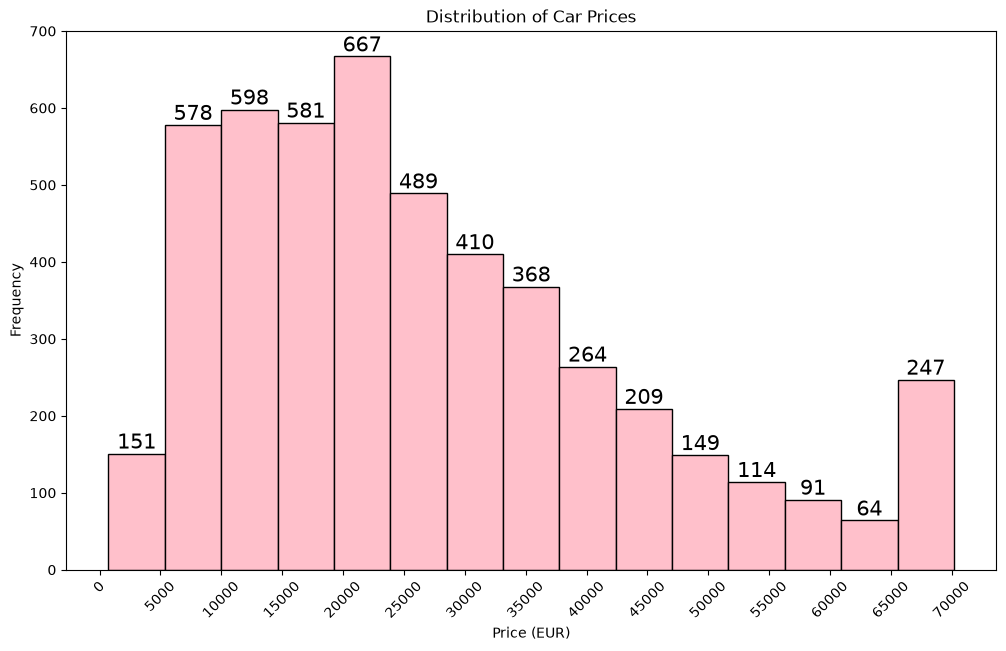

In [20]:
plt.figure(figsize=(12, 7))
bar = plt.hist(df_a['price_eur'], bins=15, color="pink", edgecolor="black", align="mid")
plt.xticks(range(0, 71000, 5000), rotation=45)
plt.xlabel("Price (EUR)")
plt.ylabel("Frequency")
plt.title("Distribution of Car Prices")
plt.bar_label(bar[2],color='black', fontsize=15)
plt.show()

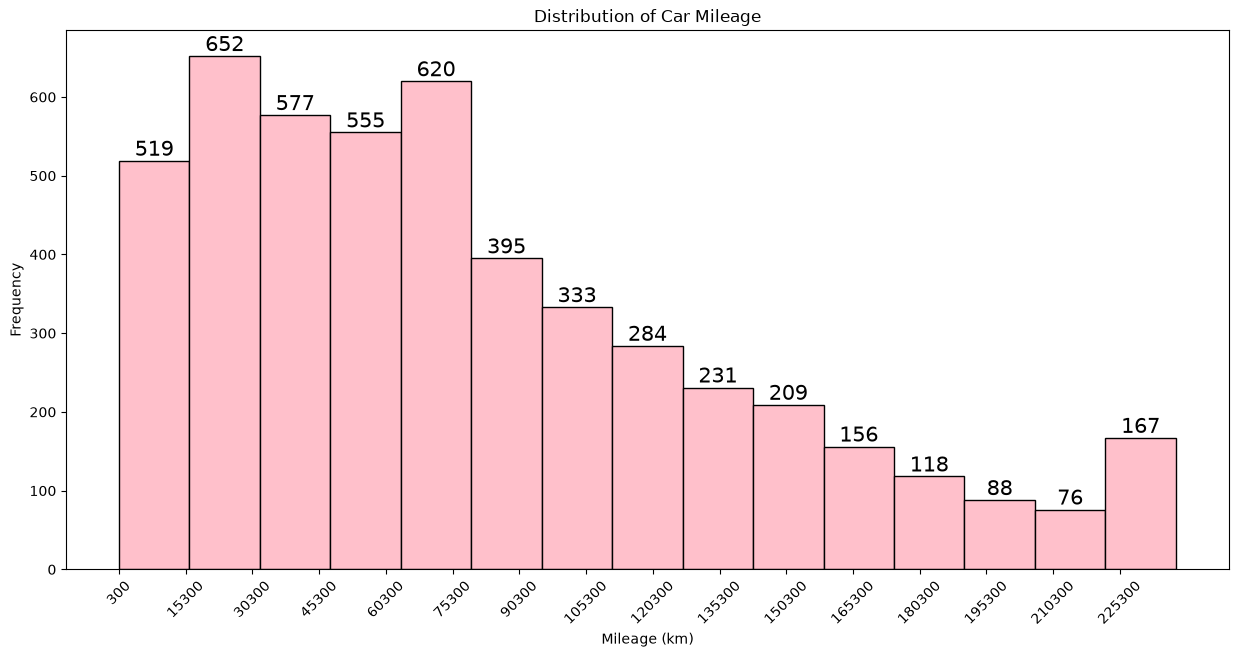

In [21]:
plt.figure(figsize=(15, 7))
bar = plt.hist(df_a['mileage_km'], bins=15, color="pink", edgecolor="black", align="mid")
plt.xticks(range(300, 238000, 15000), rotation=45)
plt.xlabel("Mileage (km)")
plt.ylabel("Frequency")
plt.title("Distribution of Car Mileage")
plt.bar_label(bar[2], color='black', fontsize=15)
plt.show()

C:\Users\gooda\AppData\Local\Temp\ipykernel_12336\3795559633.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x=df_a['engine_size_l'], vert=False, patch_artist=True, boxprops=dict(color='purple'),medianprops=dict(color='yellow'))


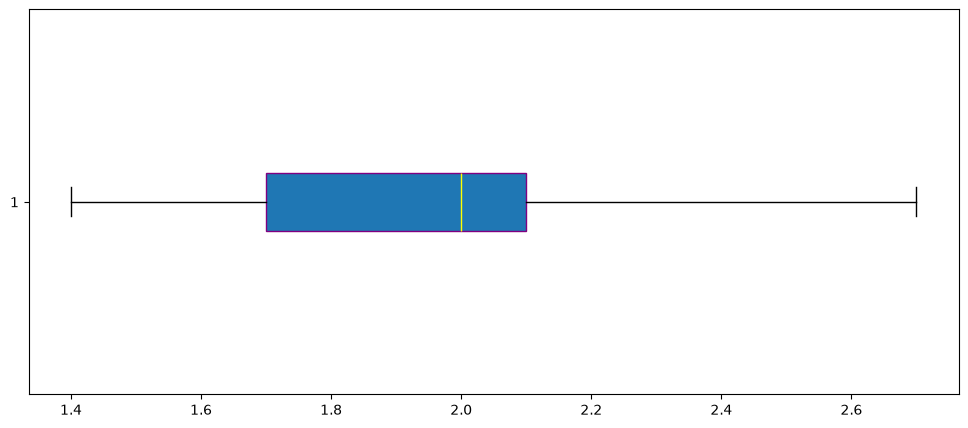

In [22]:
plt.figure(figsize=(12,5))
plt.boxplot(x=df_a['engine_size_l'], vert=False, patch_artist=True, boxprops=dict(color='purple'),medianprops=dict(color='yellow'))
plt.show()

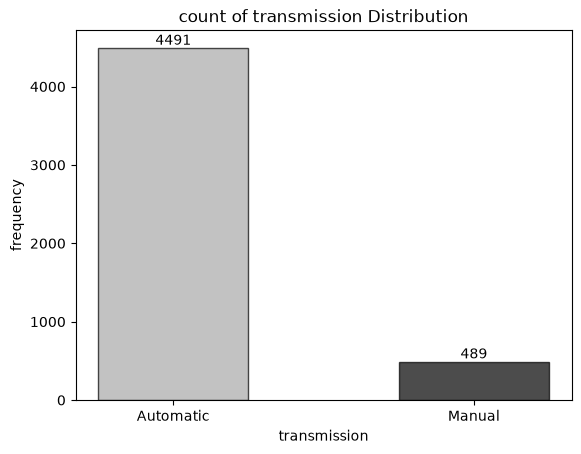

In [23]:
bar = plt.bar(x=df_a['transmission'].value_counts().index, height=df_a['transmission'].value_counts().values, color=[ 'darkgray', 'black'], edgecolor='black',alpha=0.7, width=0.5)
plt.xlabel('transmission')
plt.ylabel('frequency') 
plt.title('count of transmission Distribution')
plt.bar_label(bar)
plt.show()

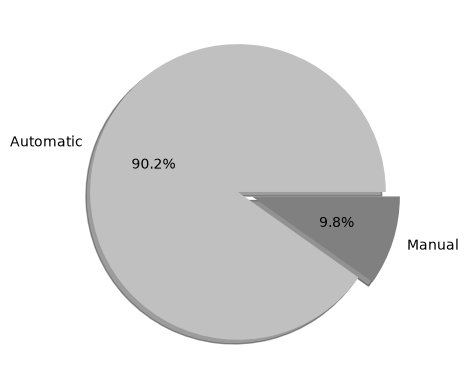

In [24]:
plt.pie(labels=df_a['transmission'].value_counts().index, x=df_a['transmission'].value_counts().values, autopct='%1.1f%%', colors=['silver', 'gray'], explode=[0.05, 0.05], shadow=True)
plt.show()

In [25]:
df_a.head()

,model,year,price_eur,mileage_km,fuel_type,transmission,engine_size_l,horsepower,previous_owners
0,S-Class,2024.0,70167.25,19381.0,Petrol,Automatic,2.7,356.0,1.0
1,CLA,2021.0,30306.00,48532.0,Diesel,Automatic,1.9,226.0,1.0
2,GLC,2021.0,34221.00,60837.0,Petrol,Automatic,2.1,223.0,1.0
3,C-Class,2013.0,7160.00,168143.0,Diesel,Manual,2.1,166.0,3.0
4,A-Class,2012.0,5383.00,122613.0,Petrol,Automatic,1.7,166.0,3.0


In [26]:
#KPIS_1
Total_Price=round(df_a['price_eur'].sum())
Total_Price

135487557

In [27]:
#KPIS_2
Avg_Km=round(df_a["mileage_km"].mean())
Avg_Km

81112

In [28]:
#KPIS_3
Avg_owners=round(df_a["previous_owners"].mean())
Avg_owners

2

In [29]:
kpi_1 = go.Figure(go.Indicator(
    mode = "number",
    value = Total_Price,
    title = {"text": "Total_Price"},
    number = {"prefix": "$"}
))
kpi_1.show()

In [30]:
kpi_2 = go.Figure(go.Indicator(
    mode = "number",
    value = Avg_Km,
    title = {"text": "Avg_Km"}
))
kpi_2.show()

In [31]:
kpi_3 = go.Figure(go.Indicator(
    mode = "number",
    value = Avg_owners,
    title = {"text": "Avg_owners"}
))
kpi_3.show()

In [32]:
df_a["year"].value_counts()

year
2024.0    532
2023.0    517
2022.0    495
2021.0    493
2020.0    487
2018.0    377
2019.0    359
2017.0    312
2016.0    294
2015.0    272
2014.0    243
2013.0    187
2012.0    159
2011.0    151
2010.0    102
Name: count, dtype: int64

In [33]:
price_by_year=df_a.groupby("year")["price_eur"].mean().reset_index()
price_by_year

,year,price_eur
0,2010.0,6950.480392
1,2011.0,7465.052980
2,2012.0,8907.226415
3,2013.0,10068.438503
4,2014.0,12094.481481
5,2015.0,14044.801471
6,2016.0,15266.445578
7,2017.0,18439.516026
8,2018.0,22472.344828
9,2019.0,25806.192897


In [34]:
#figure_1(price over years)
fig_line=px.line(price_by_year,x="year",y="price_eur",title="Avg price over years")
fig_line.update_layout(title_x=0.5)
fig_line.show()

In [35]:
df_a.head()

,model,year,price_eur,mileage_km,fuel_type,transmission,engine_size_l,horsepower,previous_owners
0,S-Class,2024.0,70167.25,19381.0,Petrol,Automatic,2.7,356.0,1.0
1,CLA,2021.0,30306.00,48532.0,Diesel,Automatic,1.9,226.0,1.0
2,GLC,2021.0,34221.00,60837.0,Petrol,Automatic,2.1,223.0,1.0
3,C-Class,2013.0,7160.00,168143.0,Diesel,Manual,2.1,166.0,3.0
4,A-Class,2012.0,5383.00,122613.0,Petrol,Automatic,1.7,166.0,3.0


In [36]:
#price by model
price_model=df_a.groupby("model")["price_eur"].sum().reset_index().sort_values(by="price_eur",ascending=False)
price_model

,model,price_eur
2,C-Class,21573519.75
4,E-Class,21201905.50
9,GLC,17261680.00
0,A-Class,15072954.75
10,GLE,14086602.25
11,S-Class,12416768.75
8,GLA,10149871.00
7,G-Class,5951688.75
3,CLA,5628023.00
5,EQC,5447635.00


In [37]:
#figure_2(price by model)
fig_bar=px.bar(price_model,x="model",y="price_eur",title="Total price by model")
fig_bar.update_layout(title_x=0.5)
fig_bar.show()

In [38]:
count_transmission=df_a["transmission"].value_counts().reset_index()
count_transmission

,transmission,count
0,Automatic,4491
1,Manual,489


In [39]:
#figure_3(count_transmission)
fig_pie=px.pie(count_transmission,names="transmission",values="count",title="Ttransmission_count",hole=0.5)
fig_pie.update_layout(title_x=0.5)
fig_pie.show()

In [40]:
# أولاً: تجهيز البيانات وحفظها في متغير (مثلاً count_transmission)
df_trans = df_a['transmission'].value_counts(normalize=True).reset_index()
df_trans.columns = ['transmission', 'proportion'] # تأكد من أسماء الأعمدة بعد الـ reset_index

# ثانياً: رسم الـ Donut Chart بشكل صحيح
fig = px.pie(
    df_trans, 
    names='transmission', 
    values='proportion', 
    template='plotly_dark', 
    hole=0.5,
    title='Transmission Proportion'
)

fig.update_traces(textinfo='percent+value+label', pull=[0.0, 0.2])
fig.update_layout(title_x=0.5)
fig.show()

In [41]:
count_fule=df_a["fuel_type"].value_counts().reset_index()
count_fule

,fuel_type,count
0,Petrol,2403
1,Diesel,1663
2,Hybrid,661
3,Electric,253


In [42]:
#figure_4(count Fule Type)
fig_pie_1=px.pie(count_fule,names="fuel_type",values="count",title="ount Fule Type",hole=0.5)
fig_pie_1.update_layout(title_x=0.5)
fig_pie_1.show()

In [43]:
fig_scat = px.scatter(df_a,x="mileage_km",y="price_eur",title="mileage_km vs price_eur",color='model',hover_name='transmission')
fig_scat.update_layout(title_x=0.5)
fig_scat.show()

In [44]:
# Figure_6 (Distrbution of Price)
fig_his = px.histogram(df_a,
    x="price_eur",
    nbins=15,
    title="Distrbuation of Price"
)
fig_his.update_traces(texttemplate="%{y}", textposition="outside")
fig_his.update_xaxes(dtick=5000)
fig_his.show()

In [45]:
fig_box = px.box(data_frame=df_a,x="price_eur",color_discrete_sequence=["#EBE6E7"],template='plotly_dark',title="Distribution of price")
fig_box.update_layout(title_x=0.5,xaxis_title="price_eur")
fig_box.show()

In [46]:
fig7 = px.imshow(df_a.corr(numeric_only=True))
fig7.show()

In [47]:
fig7 = px.imshow(df_a.corr(numeric_only=True), color_continuous_scale='Blues',text_auto=".2f",title="correlation Heatmap")
fig7.show()

In [48]:
# ==========================================
# 3. Initialize Dashboard Layout (3x3 Grid)
# ==========================================
fig = make_subplots(
    rows=3,
    cols=3,
    specs=[
        [{'type': 'domain'}, {'type': 'domain'}, {'type': 'domain'}],  # Row 1: KPIs
        [{'type': 'xy'}, {'type': 'xy'}, {'type': 'xy'}],  # Row 2: Charts 1, 2, 3
        [
            {'type': 'xy'},
            {'type': 'domain'},
            {'type': 'domain'},
        ],  # Row 3: Charts 4, 5, 6
    ],
    subplot_titles=(
        '',
        '',
        '',  # Empty titles for KPI row
        'Avg Price Over year',  
        'Total Price by model',
        'Price vs Mileage',
        'Fuel Type Share',
        "price vs km",
        'Horse Power Distribution',  # Row 3 chart titles
    ),
    vertical_spacing=0.15,  # مسافة رأسية أوسع لمنع التداخل
    horizontal_spacing=0.08,
    row_heights=[0.20, 0.40, 0.40],  # ضبط مساحة كل صف
)

# ==========================================
# 4. Add 3 KPIs to Row 1
# ==========================================

# KPI 1: Total_Price
for trace in kpi_1.data:
  fig.add_trace(trace, row=1, col=1)

# KPI 2: Average Price
for trace in kpi_2.data:
  fig.add_trace(trace, row=1, col=2)

# KPI 3: Average Mileage
for trace in kpi_3.data:
  fig.add_trace(trace, row=1, col=3)

# Chart 1 (Row 2, Col 1): Bar Chart - Price by Model
for trace in fig_bar.data:
  fig.add_trace(trace, row=2, col=1)

# Chart 2 (Row 2, Col 2): Line Chart - Price Over Years
for trace in fig_line.data:
  fig.add_trace(trace, row=2, col=2)

# Chart 3 (Row 2, Col 3): Scatter Chart - Price vs Mileage
for trace in fig_scat.data:
  fig.add_trace(trace, row=2, col=3)

# Chart 4 (Row 3, Col 1): Histogram - Horse Power Distribution
for trace in fig_his.data:
  fig.add_trace(trace, row=3, col=1)

# Chart 5 (Row 3, Col 2): Pie Chart - Fuel Type Share
for trace in fig_pie.data:
  fig.add_trace(trace, row=3, col=2)

# Chart 6 (Row 3, Col 3): Donut Chart - Transmission Share
for trace in fig_pie_1.data:
  fig.add_trace(trace, row=3, col=3)


# ==========================================
# 6. Apply Final Formatting and Export
# ==========================================
fig.update_layout(
    template='plotly_dark',
    height=1300,  # زيادة الارتفاع الكلي عشان يكفي العناصر براحتها
    title_text='Mercdes Analytics Dashboard',
    title_x=0.5,
    title_font=dict(size=22),
    showlegend=False,
    margin=dict(t=120, b=50, l=50, r=50),  # حواشي مريحة لمنع قص النصوص
)

# Display the dashboard interactive figure
fig.show()

In [49]:
# حفظ الداشبورد كملف HTML تفاعلي لفتحه في أي متصفح
fig.write_html('mercedes_dashboard.html')